In [154]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    "d2/train",
    image_size=(224,224),
    batch_size=32,
    
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "d2/validation",
    image_size=(224,224),
    batch_size=32,
    
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "d2/test",
    image_size=(224,224),
    batch_size=32,
     shuffle=False
)

Found 1096 files belonging to 4 classes.
Found 235 files belonging to 4 classes.
Found 238 files belonging to 4 classes.


In [155]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),  
    layers.RandomRotation(0.1),                  
    layers.RandomZoom(0.1),                        
    layers.RandomContrast(0.1),                   
])

In [156]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([

    layers.Rescaling(1./255, input_shape=(224,224,3)),

    data_augmentation,

    layers.Conv2D(32, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(256, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

model.summary()

C:\Users\MSI\anaconda3\envs\my_env\lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_12 (Rescaling)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_23 (Sequential)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_50 (Conv2D)                   │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_50 (MaxPooling2D)      │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_51 (Conv2D)                   │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_51 (MaxPooling2D)      │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_52 (Conv2D)                   │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_52 (MaxPooling2D)      │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_53 (Conv2D)                   │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_53 (MaxPooling2D)      │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_12 (Flatten)                 │ (None, 50176)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_36 (Dense)                     │ (None, 256)                 │      12,845,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_37 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_25 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_38 (Dense)                     │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,267,140 (50.61 MB)

 Trainable params: 13,267,140 (50.61 MB)

 Non-trainable params: 0 (0.00 B)

In [157]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [158]:
class_weights = {
    0: 1.0,   # damaged
    1: 2.0,
    2: 1.0,
    3: 1.0
}

In [159]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [160]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

y = []
for _, labels in train_ds:
    y.extend(labels.numpy())

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y),
    y=y
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(0.9194630872483222), 1: np.float64(1.2924528301886793), 2: np.float64(0.9288135593220339), 3: np.float64(0.9415807560137457)}


In [161]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    class_weight=class_weights,
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 470ms/step - accuracy: 0.2819 - loss: 1.5326 - val_accuracy: 0.4213 - val_loss: 1.3747
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 477ms/step - accuracy: 0.3796 - loss: 1.3134 - val_accuracy: 0.3489 - val_loss: 1.3354
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 489ms/step - accuracy: 0.4827 - loss: 1.2022 - val_accuracy: 0.6298 - val_loss: 0.9701
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 508ms/step - accuracy: 0.6049 - loss: 1.0278 - val_accuracy: 0.5830 - val_loss: 1.0503
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 515ms/step - accuracy: 0.6779 - loss: 0.8821 - val_accuracy: 0.6511 - val_loss: 0.9119
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 476ms/step - accuracy: 0.6770 - loss: 0.8845 - val_accuracy: 0.6511 - val_loss: 0.8829
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 476ms/step - accuracy: 0.7099 - loss: 0.7883 - val_accuracy: 0.6936 - val_loss: 0.8042
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 486ms/step - accuracy: 0.7436 - loss: 0.7337 - val_accu

In [162]:
test_loss, test_acc = model.evaluate(test_ds)

print("Test Accuracy:", test_acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - accuracy: 0.8403 - loss: 0.4034
Test Accuracy: 0.8403361439704895


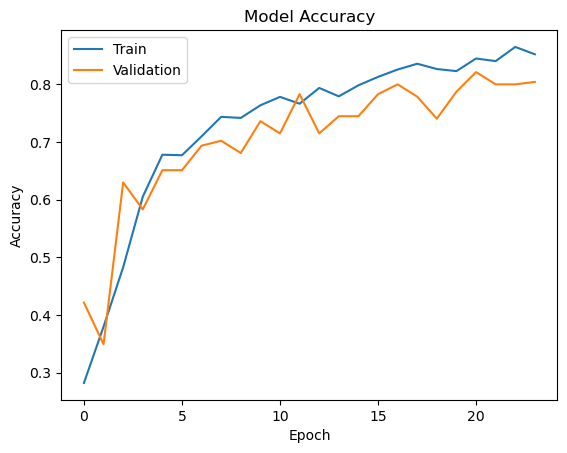

In [163]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train","Validation"])

plt.show()

In [164]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_true = np.concatenate([y.numpy() for x, y in test_ds])

predictions = model.predict(test_ds)

y_pred = np.argmax(predictions, axis=1)

print("Accuracy Score =", accuracy_score(y_true, y_pred))

print(confusion_matrix(y_true, y_pred))

print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.class_names
))

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step
Accuracy Score = 0.8403361344537815
[[48  3  9  5]
 [ 0 32  2 12]
 [ 0  3 61  0]
 [ 1  3  0 59]]
                          precision    recall  f1-score   support

Missile-Damaged Building       0.98      0.74      0.84        65
                 damaged       0.78      0.70      0.74        46
               destroyed       0.85      0.95      0.90        64
               no_damage       0.78      0.94      0.85        63

                accuracy                           0.84       238
               macro avg       0.85      0.83      0.83       238
            weighted avg       0.85      0.84      0.84       238



In [165]:
model.save("my_model_85.keras")

In [92]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

In [95]:
img_path = "rocket_destruction (22).png"

img = load_img(img_path, target_size=(224, 224))
img_array = img_to_array(img)

img_array_input = np.expand_dims(img_array, axis=0)

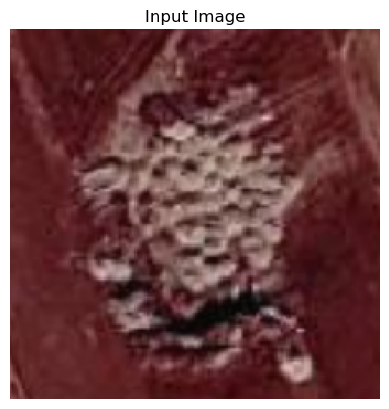

In [96]:
img_array = img_to_array(img)

plt.imshow(img_array.astype("uint8"))
plt.axis("off")
plt.title("Input Image")
plt.show()

In [97]:
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

pred = model.predict(img_array)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step


In [98]:
class_names = train_ds.class_names 

pred_class = np.argmax(pred)

print("Predicted class:", class_names[pred_class])

Predicted class: Missile-Damaged Building


In [432]:
print(train_ds.class_names)

['damaged', 'destroyed', 'no_damage']
